# Renewable Energy Generation Prediction and Weather Analysis


## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 2. Loading Datasets

In [2]:
cea = pd.read_csv(r"C:\Users\himan\Downloads\RE_Generation_(MUs)-Statewise-sourcewise_two_years.csv")
weather = pd.read_csv(r"C:\Users\himan\Downloads\00 _sample_preview.csv")

print("CEA Dataset:", cea.shape)
print("Weather Dataset:", weather.shape)

cea.head()

CEA Dataset: (797, 10)
Weather Dataset: (1000, 60)


,State,Region,Month,Wind,Solar,Biomass,Bagasse,Small Hydel,Others,Total
0,Chandigarh,NR,Apr-18,0.0,1.69,0.00,0.00,0.00,0,1.69
1,Delhi,NR,Apr-18,0.0,1.25,0.00,0.00,0.00,25.35,26.61
2,Haryana,NR,Apr-18,0.0,7.11,16.84,7.91,13.96,0,45.82
3,HP,NR,Apr-18,0.0,0.00,0.00,0.00,76.02,0,76.02
4,J&K,NR,Apr-18,0.0,0.00,0.00,0.00,28.46,0,28.46


## 3. CEA Dataset Cleaning

In [33]:
cea.columns = cea.columns.str.strip()
cea = cea.rename(columns={"Small Hydel": "Small_Hydel"})

cea["State"] = cea["State"].astype(str).str.strip()

num_cols = ["Wind", "Solar", "Biomass", "Bagasse", "Small_Hydel", "Others", "Total"]

for col in num_cols:
    cea[col] = pd.to_numeric(
        cea[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce")

cea["Date"] = pd.to_datetime(cea["Month"], format="%b-%y", errors="coerce")

cea = cea.dropna(subset=["State", "Date", "Total"])
cea = cea.drop_duplicates(subset=["State", "Date"])
cea = cea.sort_values(["Date", "State"]).reset_index(drop=True)

for col in num_cols[:-1]:
    cea[col] = cea[col].fillna(0)

print(cea.shape)
cea.head()

(722, 17)


,State,Region,Month,Wind,Solar,Biomass,Bagasse,Small_Hydel,Others,Total,Date,Month_Number,Month_Sin,Month_Cos,Total_Lag1,Total_Lag2,Total_Rolling3
0,Andaman Nicobar,ER,Jun-18,0.00,0.60,0.00,0.00,1.37,0.00,1.97,2018-06-01,6,1.224647e-16,-1.0,1.79,1.93,1.860
1,Andhra Pradesh,SR,Jun-18,1269.47,378.28,21.24,26.20,3.84,0.55,1699.58,2018-06-01,6,1.224647e-16,-1.0,890.58,863.70,877.140
2,Arunachal Pradesh,NER,Jun-18,0.00,0.08,0.00,0.00,0.03,0.00,0.11,2018-06-01,6,1.224647e-16,-1.0,0.14,0.11,0.125
3,Assam,NER,Jun-18,0.00,0.48,0.00,0.00,1.01,0.00,1.49,2018-06-01,6,1.224647e-16,-1.0,1.11,1.61,1.360
4,Bihar,ER,Jun-18,12.28,0.00,0.00,16.98,0.00,0.00,29.25,2018-06-01,6,1.224647e-16,-1.0,35.06,44.95,40.005


## 4. Performing EDA

In [35]:
print(cea.info())
print(cea.isnull().sum())
print(cea.describe())

<class 'pandas.DataFrame'>
RangeIndex: 722 entries, 0 to 721
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   State           722 non-null    str           
 1   Region          722 non-null    str           
 2   Month           722 non-null    str           
 3   Wind            722 non-null    float64       
 4   Solar           722 non-null    float64       
 5   Biomass         722 non-null    float64       
 6   Bagasse         722 non-null    float64       
 7   Small_Hydel     722 non-null    float64       
 8   Others          722 non-null    float64       
 9   Total           722 non-null    float64       
 10  Date            722 non-null    datetime64[us]
 11  Month_Number    722 non-null    int32         
 12  Month_Sin       722 non-null    float64       
 13  Month_Cos       722 non-null    float64       
 14  Total_Lag1      722 non-null    float64       
 15  Total_Lag2      7

In [5]:
print("Number of states:", cea["State"].nunique())
print("Start date:", cea["Date"].min())
print("End date:", cea["Date"].max())

Number of states: 38
Start date: 2018-04-01 00:00:00
End date: 2020-01-01 00:00:00


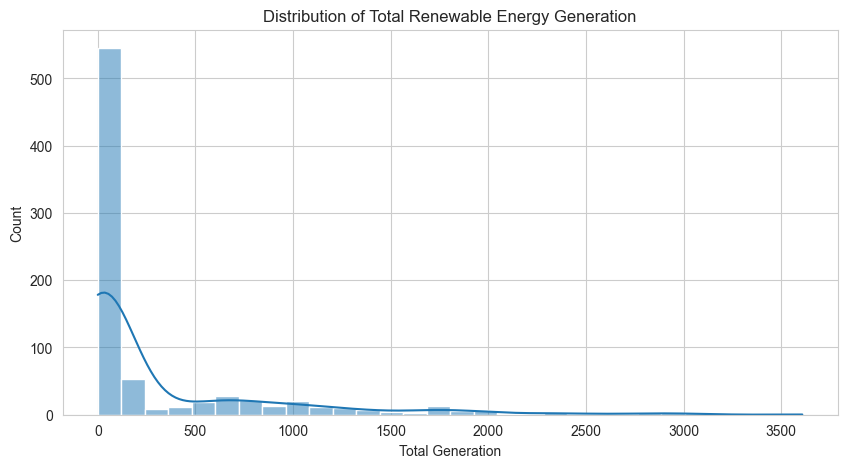

In [6]:
plt.figure(figsize=(10,5))
sns.histplot(cea["Total"], bins=30, kde=True)
plt.title("Distribution of Total Renewable Energy Generation")
plt.xlabel("Total Generation")
plt.show()

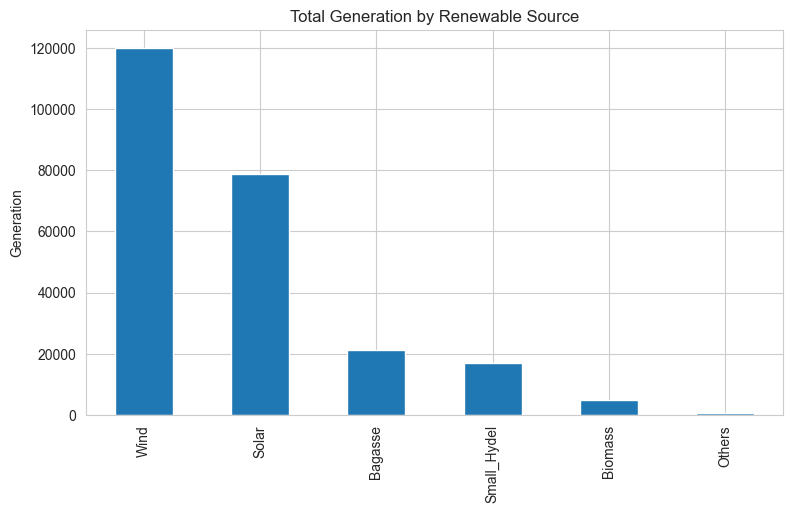

In [7]:
source_cols = ["Wind", "Solar", "Biomass", "Bagasse", "Small_Hydel", "Others"]

cea[source_cols].sum().sort_values(ascending=False).plot(
    kind="bar", figsize=(9,5)
)
plt.title("Total Generation by Renewable Source")
plt.ylabel("Generation")
plt.show()

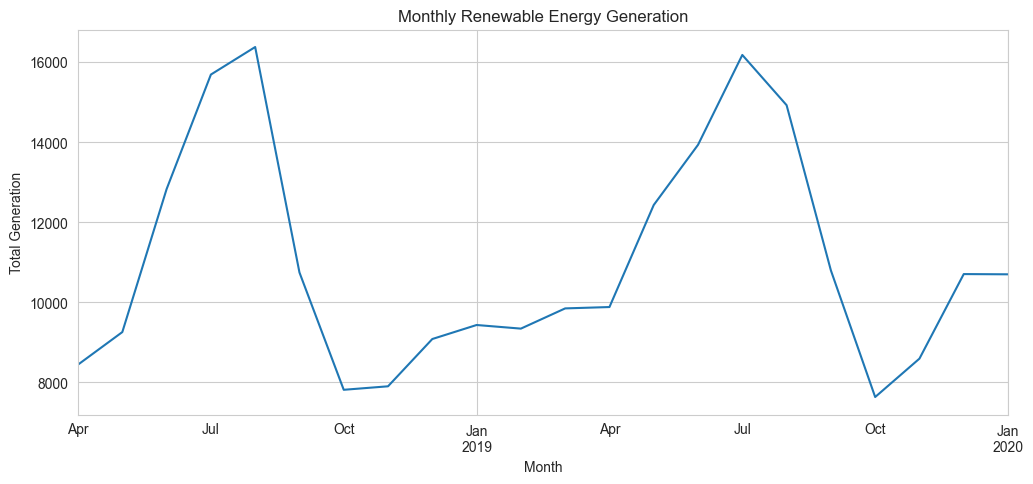

In [8]:
monthly = cea.groupby("Date")["Total"].sum()

plt.figure(figsize=(12,5))
monthly.plot()
plt.title("Monthly Renewable Energy Generation")
plt.xlabel("Month")
plt.ylabel("Total Generation")
plt.show()

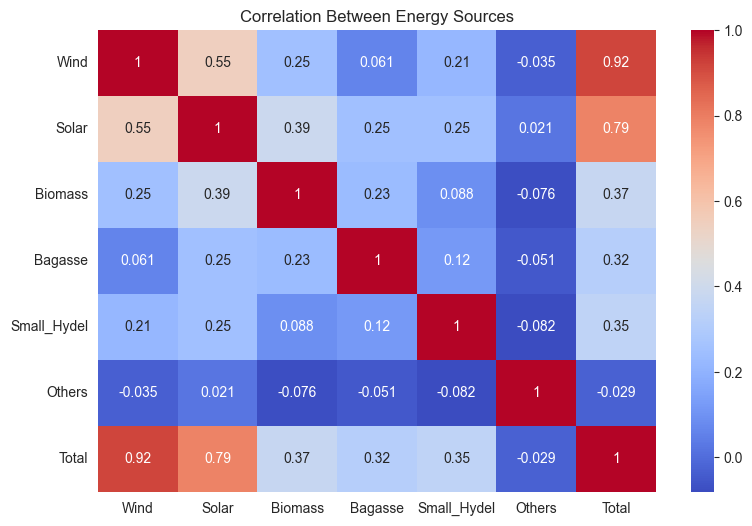

In [9]:
plt.figure(figsize=(9,6))
sns.heatmap(cea[source_cols + ["Total"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Between Energy Sources")
plt.show()

## 5. Feature Engineering

In [10]:
cea["Month_Number"] = cea["Date"].dt.month
cea["Month_Sin"] = np.sin(2 * np.pi * cea["Month_Number"] / 12)
cea["Month_Cos"] = np.cos(2 * np.pi * cea["Month_Number"] / 12)

cea["Total_Lag1"] = cea.groupby("State")["Total"].shift(1)
cea["Total_Lag2"] = cea.groupby("State")["Total"].shift(2)

cea["Total_Rolling3"] = (
    cea.groupby("State")["Total"]
    .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
)

cea.head()

,State,Region,Month,Wind,Solar,Biomass,Bagasse,Small_Hydel,Others,Total,Date,Month_Number,Month_Sin,Month_Cos,Total_Lag1,Total_Lag2,Total_Rolling3
0,Andaman Nicobar,ER,Apr-18,0.00,1.22,0.00,0.00,0.72,0.00,1.93,2018-04-01,4,0.866025,-0.5,NaN,NaN,NaN
1,Andhra Pradesh,SR,Apr-18,369.77,434.23,20.62,30.54,7.89,0.64,863.70,2018-04-01,4,0.866025,-0.5,NaN,NaN,NaN
2,Arunachal Pradesh,NER,Apr-18,0.00,0.09,0.00,0.00,0.03,0.00,0.11,2018-04-01,4,0.866025,-0.5,NaN,NaN,NaN
3,Assam,NER,Apr-18,0.00,0.53,0.00,0.00,1.07,0.00,1.61,2018-04-01,4,0.866025,-0.5,NaN,NaN,NaN
4,Bihar,ER,Apr-18,0.00,19.22,2.03,23.66,0.04,0.00,44.95,2018-04-01,4,0.866025,-0.5,NaN,NaN,NaN


## 6. Regression – Predicting Total Generation

We use previous generation values to predict the current month's total generation. Earlier dates are used for training and later dates for testing.

In [11]:
reg = cea.dropna(subset=["Total_Lag1", "Total_Lag2"]).copy()

dates = sorted(reg["Date"].unique())
split_date = dates[int(len(dates) * 0.8)]

train = reg[reg["Date"] <= split_date]
test = reg[reg["Date"] > split_date]

features = ["State", "Month_Sin", "Month_Cos",
            "Total_Lag1", "Total_Lag2", "Total_Rolling3"]

X_train = pd.get_dummies(train[features], columns=["State"])
X_test = pd.get_dummies(test[features], columns=["State"])

X_train, X_test = X_train.align(
    X_test, join="left", axis=1, fill_value=0
)

y_train = train["Total"]
y_test = test["Total"]

print(X_train.shape, X_test.shape)

(612, 41) (110, 41)


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append([name, mae, mse, rmse, r2])

reg_result = pd.DataFrame(
    results, columns=["Model", "MAE", "MSE", "RMSE", "R2"]
)
reg_result.sort_values("RMSE")

,Model,MAE,MSE,RMSE,R2
2,Random Forest,42.926592,13476.858468,116.089872,0.945718
1,Decision Tree,50.768219,16297.597245,127.662043,0.934356
0,Linear Regression,77.520437,18325.635606,135.372211,0.926188


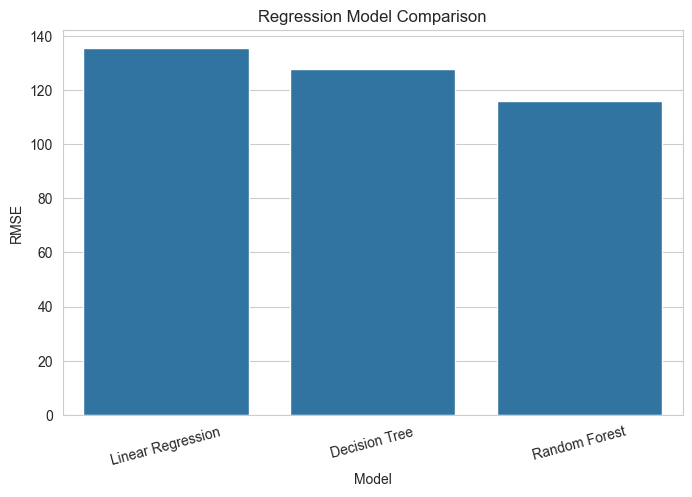

In [13]:
plt.figure(figsize=(8,5))
sns.barplot(data=reg_result, x="Model", y="RMSE")
plt.title("Regression Model Comparison")
plt.xticks(rotation=15)
plt.show()

In [14]:
# Polynomial Regression
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train.select_dtypes(include=np.number))
X_test_poly = poly.transform(X_test.select_dtypes(include=np.number))

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

poly_pred = poly_model.predict(X_test_poly)

print("Polynomial Regression MAE:", mean_absolute_error(y_test, poly_pred))
print("Polynomial Regression RMSE:", np.sqrt(mean_squared_error(y_test, poly_pred)))
print("Polynomial Regression R2:", r2_score(y_test, poly_pred))

Polynomial Regression MAE: 75.91178929166412
Polynomial Regression RMSE: 154.86413154313783
Polynomial Regression R2: 0.903401522380924


## 7. Classification – Generation Level

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

class_train = train.copy()
class_test = test.copy()

q1 = class_train["Total"].quantile(1/3)
q2 = class_train["Total"].quantile(2/3)

class_train["Level"] = pd.cut(
    class_train["Total"],
    bins=[-np.inf, q1, q2, np.inf],
    labels=["Low", "Medium", "High"]
)
class_test["Level"] = pd.cut(
    class_test["Total"],
    bins=[-np.inf, q1, q2, np.inf],
    labels=["Low", "Medium", "High"]
)

X_train_c = pd.get_dummies(class_train[features], columns=["State"])
X_test_c = pd.get_dummies(class_test[features], columns=["State"])
X_train_c, X_test_c = X_train_c.align(
    X_test_c, join="left", axis=1, fill_value=0
)

y_train_c = class_train["Level"]
y_test_c = class_test["Level"]

print(y_train_c.value_counts())
print(y_test_c.value_counts())

Level
Low       206
High      204
Medium    202
Name: count, dtype: int64
Level
Medium    42
Low       37
High      31
Name: count, dtype: int64


In [16]:
class_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC()
}

class_results = []

for name, model in class_models.items():
    model.fit(X_train_c, y_train_c)
    pred = model.predict(X_test_c)

    acc = accuracy_score(y_test_c, pred)
    pre = precision_score(y_test_c, pred, average="weighted", zero_division=0)
    rec = recall_score(y_test_c, pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test_c, pred, average="weighted", zero_division=0)

    class_results.append([name, acc, pre, rec, f1])

class_result = pd.DataFrame(
    class_results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
)
class_result.sort_values("F1 Score", ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.945455,0.948701,0.945455,0.945639
1,Decision Tree,0.945455,0.948701,0.945455,0.945639
2,Random Forest,0.945455,0.948701,0.945455,0.945639
3,SVM,0.781818,0.846394,0.781818,0.766025


              precision    recall  f1-score   support

        High       0.89      1.00      0.94        31
         Low       1.00      0.95      0.97        37
      Medium       0.95      0.90      0.93        42

    accuracy                           0.95       110
   macro avg       0.95      0.95      0.95       110
weighted avg       0.95      0.95      0.95       110



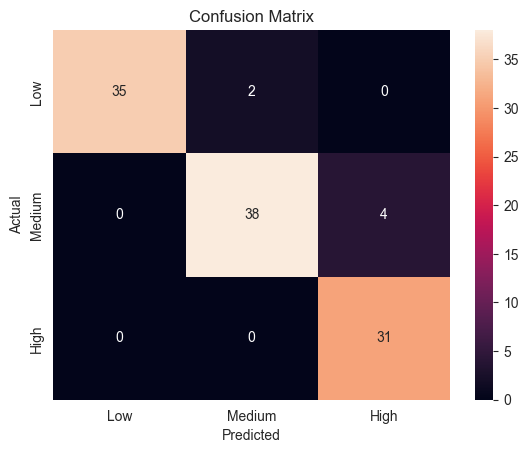

In [17]:
best_model = RandomForestClassifier(n_estimators=100, random_state=42)
best_model.fit(X_train_c, y_train_c)
class_pred = best_model.predict(X_test_c)

print(classification_report(y_test_c, class_pred, zero_division=0))

cm = confusion_matrix(y_test_c, class_pred, labels=["Low", "Medium", "High"])
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Low", "Medium", "High"],
            yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 8. Clustering – Grouping States

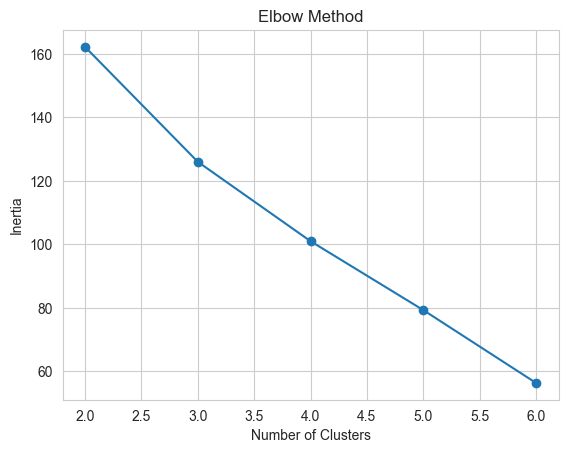

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

state_data = cea.groupby("State")[source_cols + ["Total"]].mean().reset_index()

scaler = StandardScaler()
state_scaled = scaler.fit_transform(state_data[source_cols + ["Total"]])

inertia = []

for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(state_scaled)
    inertia.append(km.inertia_)

plt.plot(range(2, 7), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [19]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
state_data["KMeans_Cluster"] = kmeans.fit_predict(state_scaled)

for method in ["single", "complete", "average"]:
    agg = AgglomerativeClustering(n_clusters=3, linkage=method)
    state_data["Cluster_" + method] = agg.fit_predict(state_scaled)

state_data.head()

,State,Wind,Solar,Biomass,Bagasse,Small_Hydel,Others,Total,KMeans_Cluster,Cluster_single,Cluster_complete,Cluster_average
0,Andaman Nicobar,0.000000,1.058182,0.000000,0.000000,0.985909,0.000000,2.042273,1,0,0,0
1,Andhra Pradesh,714.599545,436.228182,14.587727,16.006818,19.818182,0.609545,1201.850455,0,0,2,0
2,Arunachal Pradesh,0.000000,0.111364,0.000000,0.000000,0.050455,0.000000,0.161818,1,0,0,0
3,Assam,0.000000,0.534545,0.000000,0.000000,2.875000,0.000000,3.408636,1,0,0,0
4,Bihar,0.558182,14.097727,1.172273,16.523636,1.815909,0.000000,34.167727,1,0,0,0


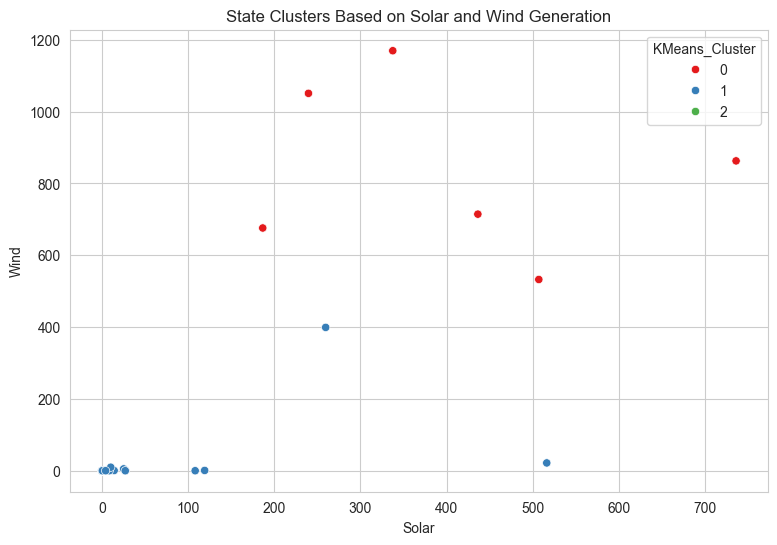

In [20]:
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=state_data, x="Solar", y="Wind",
    hue="KMeans_Cluster", palette="Set1"
)
plt.title("State Clusters Based on Solar and Wind Generation")
plt.show()

## 9. Association Pattern Analysis

In [21]:
# A source is present when its generation value is greater than zero

transactions = []

for i, row in cea.iterrows():
    present = []
    for source in source_cols:
        if row[source] > 0:
            present.append(source)
    transactions.append(present)

rules = []

for a in source_cols:
    for b in source_cols:
        if a != b:
            count_a = sum(a in t for t in transactions)
            count_b = sum(b in t for t in transactions)
            count_both = sum(a in t and b in t for t in transactions)

            if count_a > 0 and count_b > 0:
                support = count_both / len(transactions)
                confidence = count_both / count_a
                lift = confidence / (count_b / len(transactions))

                rules.append([a, b, support, confidence, lift])

rules_df = pd.DataFrame(
    rules, columns=["Source A", "Source B", "Support", "Confidence", "Lift"]
)
rules_df.sort_values("Lift", ascending=False).head(10)

,Source A,Source B,Support,Confidence,Lift
25,Others,Wind,0.106650,0.745614,2.776890
4,Wind,Others,0.106650,0.397196,2.776890
1,Wind,Biomass,0.237139,0.883178,2.346308
10,Biomass,Wind,0.237139,0.630000,2.346308
28,Others,Bagasse,0.094103,0.657895,2.269879
19,Bagasse,Others,0.094103,0.324675,2.269879
14,Biomass,Others,0.115433,0.306667,2.143977
27,Others,Biomass,0.115433,0.807018,2.143977
17,Bagasse,Biomass,0.233375,0.805195,2.139134
12,Biomass,Bagasse,0.233375,0.620000,2.139134


## 10. NASA Weather Dataset – Cleaning and EDA

In [22]:
weather.columns = weather.columns.str.strip()

if "datetime" in weather.columns:
    weather["datetime"] = pd.to_datetime(weather["datetime"], errors="coerce")
else:
    weather["datetime"] = pd.to_datetime(
        dict(year=weather["YEAR"], month=weather["MO"],
             day=weather["DY"], hour=weather["HR"]),
        errors="coerce"
    )

weather_cols = ["ALLSKY_SFC_SW_DWN", "T2M", "RH2M", "WS10M", "PRECTOTCORR"]

for col in weather_cols:
    weather[col] = pd.to_numeric(weather[col], errors="coerce")

weather = weather.dropna(subset=weather_cols + ["datetime"])

print(weather.shape)
print(weather.info())
print(weather.isnull().sum())
print(weather[weather_cols].describe())
weather.head()

(1000, 60)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   YEAR                1000 non-null   int64         
 1   MO                  1000 non-null   int64         
 2   DY                  1000 non-null   int64         
 3   HR                  1000 non-null   int64         
 4   ALLSKY_SFC_SW_DWN   1000 non-null   float64       
 5   T2M                 1000 non-null   float64       
 6   RH2M                1000 non-null   float64       
 7   WS10M               1000 non-null   float64       
 8   PRECTOTCORR         1000 non-null   float64       
 9   ALLSKY_KT           490 non-null    float64       
 10  T2MDEW              1000 non-null   float64       
 11  PS                  1000 non-null   float64       
 12  WS2M                1000 non-null   float64       
 13  WD10M               1000 non-null   float64      

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,RH2M,WS10M,PRECTOTCORR,ALLSKY_KT,...,lag_3,lag_6,lag_12,lag_24,lag_168,rolling_mean_24,rolling_std_24,rolling_mean_168,rolling_max_24,rolling_min_24
0,2016,1,1,0,0.0,16.32,80.07,1.68,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
1,2016,1,1,1,0.0,15.78,82.76,1.62,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
2,2016,1,1,2,0.0,15.31,84.99,1.56,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
3,2016,1,1,3,0.0,14.89,87.21,1.48,0.0,NaN,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
4,2016,1,1,4,0.0,14.62,88.96,1.32,0.0,NaN,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0


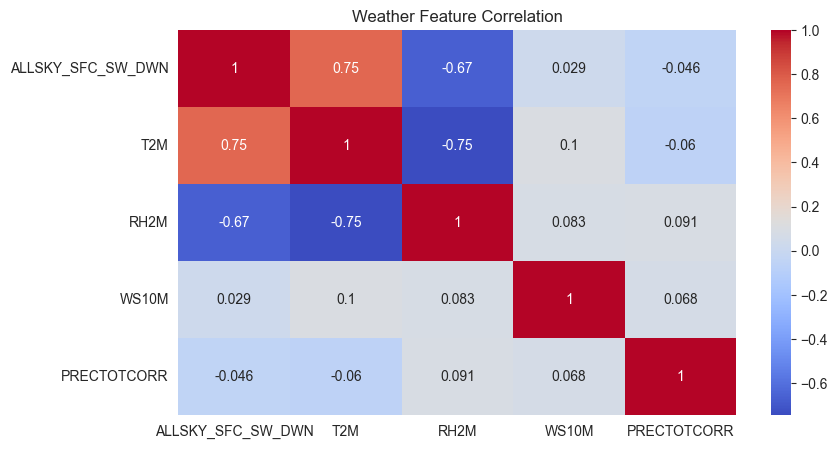

In [23]:
plt.figure(figsize=(9,5))
sns.heatmap(weather[weather_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Weather Feature Correlation")
plt.show()

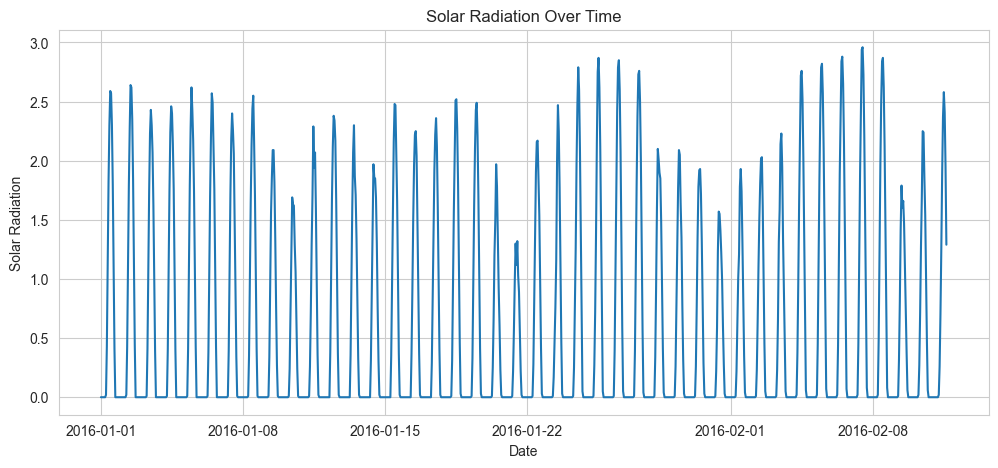

In [24]:
plt.figure(figsize=(12,5))
plt.plot(weather["datetime"], weather["ALLSKY_SFC_SW_DWN"])
plt.xlabel("Date")
plt.ylabel("Solar Radiation")
plt.title("Solar Radiation Over Time")
plt.show()

## 11. Weather Regression – Predicting Solar Radiation

In [25]:
weather["Hour"] = weather["datetime"].dt.hour
weather["Month"] = weather["datetime"].dt.month

weather_features = ["T2M", "RH2M", "WS10M", "PRECTOTCORR", "Hour", "Month"]

X = weather[weather_features]
y = weather["ALLSKY_SFC_SW_DWN"]

split = int(len(weather) * 0.8)

X_train_w = X.iloc[:split]
X_test_w = X.iloc[split:]
y_train_w = y.iloc[:split]
y_test_w = y.iloc[split:]

X_train_w = X_train_w.fillna(X_train_w.median())
X_test_w = X_test_w.fillna(X_train_w.median())

weather_scaler = StandardScaler()
X_train_w = weather_scaler.fit_transform(X_train_w)
X_test_w = weather_scaler.transform(X_test_w)

In [26]:
weather_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

weather_results = []

for name, model in weather_models.items():
    model.fit(X_train_w, y_train_w)
    pred = model.predict(X_test_w)

    mae = mean_absolute_error(y_test_w, pred)
    mse = mean_squared_error(y_test_w, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test_w, pred)

    weather_results.append([name, mae, mse, rmse, r2])

weather_result = pd.DataFrame(
    weather_results, columns=["Model", "MAE", "MSE", "RMSE", "R2"]
)
weather_result.sort_values("RMSE")

,Model,MAE,MSE,RMSE,R2
1,Random Forest,0.099305,0.031300,0.176919,0.966475
0,Linear Regression,0.371517,0.228243,0.477748,0.755534


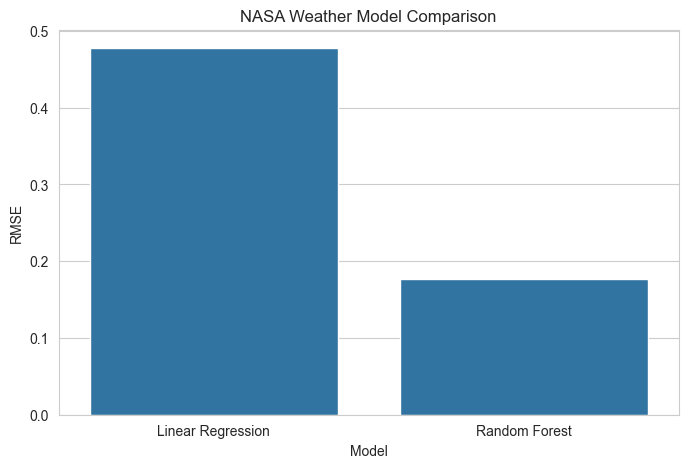

In [27]:
plt.figure(figsize=(8,5))
sns.barplot(data=weather_result, x="Model", y="RMSE")
plt.title("NASA Weather Model Comparison")
plt.show()

## 12. PCA – Dimensionality Reduction

Explained variance:
[0.3390893  0.19852133 0.16981299 0.15818116 0.09931189 0.03508333]


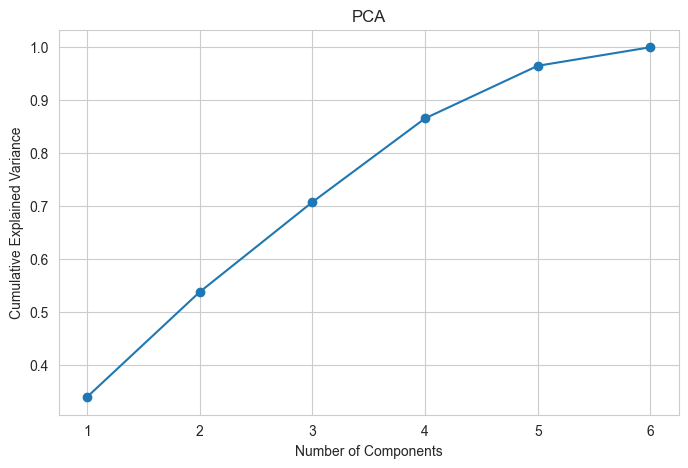

In [28]:
from sklearn.decomposition import PCA

pca = PCA()
pca_result = pca.fit_transform(X_train_w)

print("Explained variance:")
print(pca.explained_variance_ratio_)

plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_), marker="o"
)
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA")
plt.show()

## 13. Weather Clustering

In [29]:
weather_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
weather["Weather_Cluster"] = weather_kmeans.fit_predict(
    weather_scaler.transform(
        weather[weather_features].fillna(weather[weather_features].median())
    )
)

weather[["datetime", "ALLSKY_SFC_SW_DWN", "Weather_Cluster"]].head()

,datetime,ALLSKY_SFC_SW_DWN,Weather_Cluster
0,2016-01-01 00:00:00,0.0,2
1,2016-01-01 01:00:00,0.0,2
2,2016-01-01 02:00:00,0.0,2
3,2016-01-01 03:00:00,0.0,2
4,2016-01-01 04:00:00,0.0,2


## 14. Saving Results